<div style="font-family:'Segoe UI',Roboto,Helvetica,Arial,sans-serif;max-width:900px;margin:0 auto;border-radius:16px;overflow:hidden;box-shadow:0 4px 20px rgba(0,0,0,0.12);border:1px solid #e2e2e2;">

<div style="background:linear-gradient(135deg,#002855 0%,#004b8d 55%,#0077c8 100%);padding:28px 20px 22px 20px;text-align:center;">
<img src="./img/ITESOLogo.png" alt="ITESO" width="260" style="margin-bottom:10px;">
<div style="color:#ffffff;font-size:15px;font-weight:600;letter-spacing:0.5px;text-transform:uppercase;opacity:0.9;">
Departamento de Electrónica, Sistemas e Informática
</div>
</div>

<div style="background-color:#ffffff;padding:26px 30px 30px 30px;text-align:center;">

<div style="color:#002855;font-size:26px;font-weight:800;margin-bottom:6px;">
Big Data Analysis
</div>

<div style="display:inline-block;background-color:#eaf4fb;color:#0077c8;font-size:13px;font-weight:700;padding:4px 14px;border-radius:20px;letter-spacing:0.5px;margin-bottom:22px;">
Autumn 2026
</div>


<hr style="border:none;border-top:2px solid #f0f0f0;margin:0 0 22px 0;">

<div style="background-color:#f7fafd;border-left:5px solid #0077c8;border-radius:8px;padding:14px 18px;text-align:left;margin-bottom:18px;">
<div style="font-size:12px;color:#7a7a7a;font-weight:600;text-transform:uppercase;letter-spacing:0.5px;margin-bottom:4px;">
Session 15
</div>
<div style="font-size:19px;color:#002855;font-weight:700;">
Big Data - Storage Solutions: Graph Stores
</div>
</div>

<div style="font-size:14px;color:#444;margin-top:20px;">
<span style="font-weight:700;color:#002855;">Profesor:</span> Pablo Camarillo Ramírez
</div>

</div>
</div>

# Create SparkSession

In [ ]:
!pip install graphframes

In [ ]:
from pcamarillor.spark_utils import SparkUtils
neo4j_connector = "org.neo4j:neo4j-connector-apache-spark_2.13:5.3.10_for_spark_3,io.graphframes:graphframes-spark3_2.13:0.9.0-spark3.5"
su = SparkUtils("Example EDA", "local[*]", spark_packages=neo4j_connector)
su.spark

# Create GraphFrames

In [ ]:
from graphframes import GraphFrame

vertices = su.spark.createDataFrame([
  ("a", "Alice"),
  ("b", "Bob"),
  ("c", "Carol")
], ["id", "name"])

edges = su.spark.createDataFrame([
  ("a","b","follows"),
  ("b","c","follows"),
  ("c","a","follows")
], ["src","dst","relationship"])

# Create the Graph
g = GraphFrame(vertices, edges)
g.vertices.show()
g.edges.show()

# Core Graph Algorithms
## PageRank

In [ ]:
results = g.pageRank(resetProbability=0.15, maxIter=10)
results.vertices.printSchema()
# Ranked vertices (descending by importance)
results.vertices \
  .select("id", "name", "pagerank") \
  .orderBy("pagerank", ascending=False) \
  .show()

# Label Propagation

In [ ]:
lpa = g.labelPropagation(maxIter=5)
lpa.show()

# Triangle counting

In [ ]:
triangle_count = g.triangleCount()
triangle_count.show()

# Degrees Distribution

## InDregree

In [ ]:
in_deg = g.inDegrees.join(vertices, "id")
in_deg.show()

## OutDegree

In [ ]:
out_deg = g.outDegrees.join(vertices, "id")
out_deg.show()

# Write data to a Neo4j Graph

## Neo4j setup
### Install Neo4j with Docker

Go to **spark** directory and run:

```
docker run \
    -d --restart always \
    --publish=7474:7474 --publish=7687:7687 \
    --env NEO4J_AUTH=neo4j/neo4j@1234 \
    --volume=./data_neo4j:/data \
    --name neo4j-iteso \
    --network spark-cluster_default \
    neo4j:community-trixie
```

## Write GraphFrames into Neo4J

In [ ]:
neo4j_url = "bolt://neo4j-iteso:7687"
neo4j_user = "neo4j"
neo4j_passwd = "neo4j@1234"

g.vertices.write \
  .format("org.neo4j.spark.DataSource") \
  .mode("Overwrite") \
  .option("url", neo4j_url) \
  .option("authentication.basic.username", neo4j_user) \
  .option("authentication.basic.password", neo4j_passwd) \
  .option("labels", ":User") \
  .option("node.keys", "id") \
  .save()

print(f"{g.vertices.count()} verticess wrote in Neo4j")


g.edges.write \
  .format("org.neo4j.spark.DataSource") \
  .mode("Overwrite") \
  .option("url", neo4j_url) \
  .option("authentication.basic.username", neo4j_user) \
  .option("authentication.basic.password", neo4j_passwd) \
  .option("relationship", "FOLLOWS") \
  .option("relationship.save.strategy", "keys") \
  .option("relationship.source.labels", ":User") \
  .option("relationship.source.save.mode", "match") \
  .option("relationship.source.node.keys", "src:id") \
  .option("relationship.target.labels", ":User") \
  .option("relationship.target.save.mode", "match") \
  .option("relationship.target.node.keys", "dst:id") \
  .save()

print(f"{g.edges.count()} edges wrote in Neo4j")

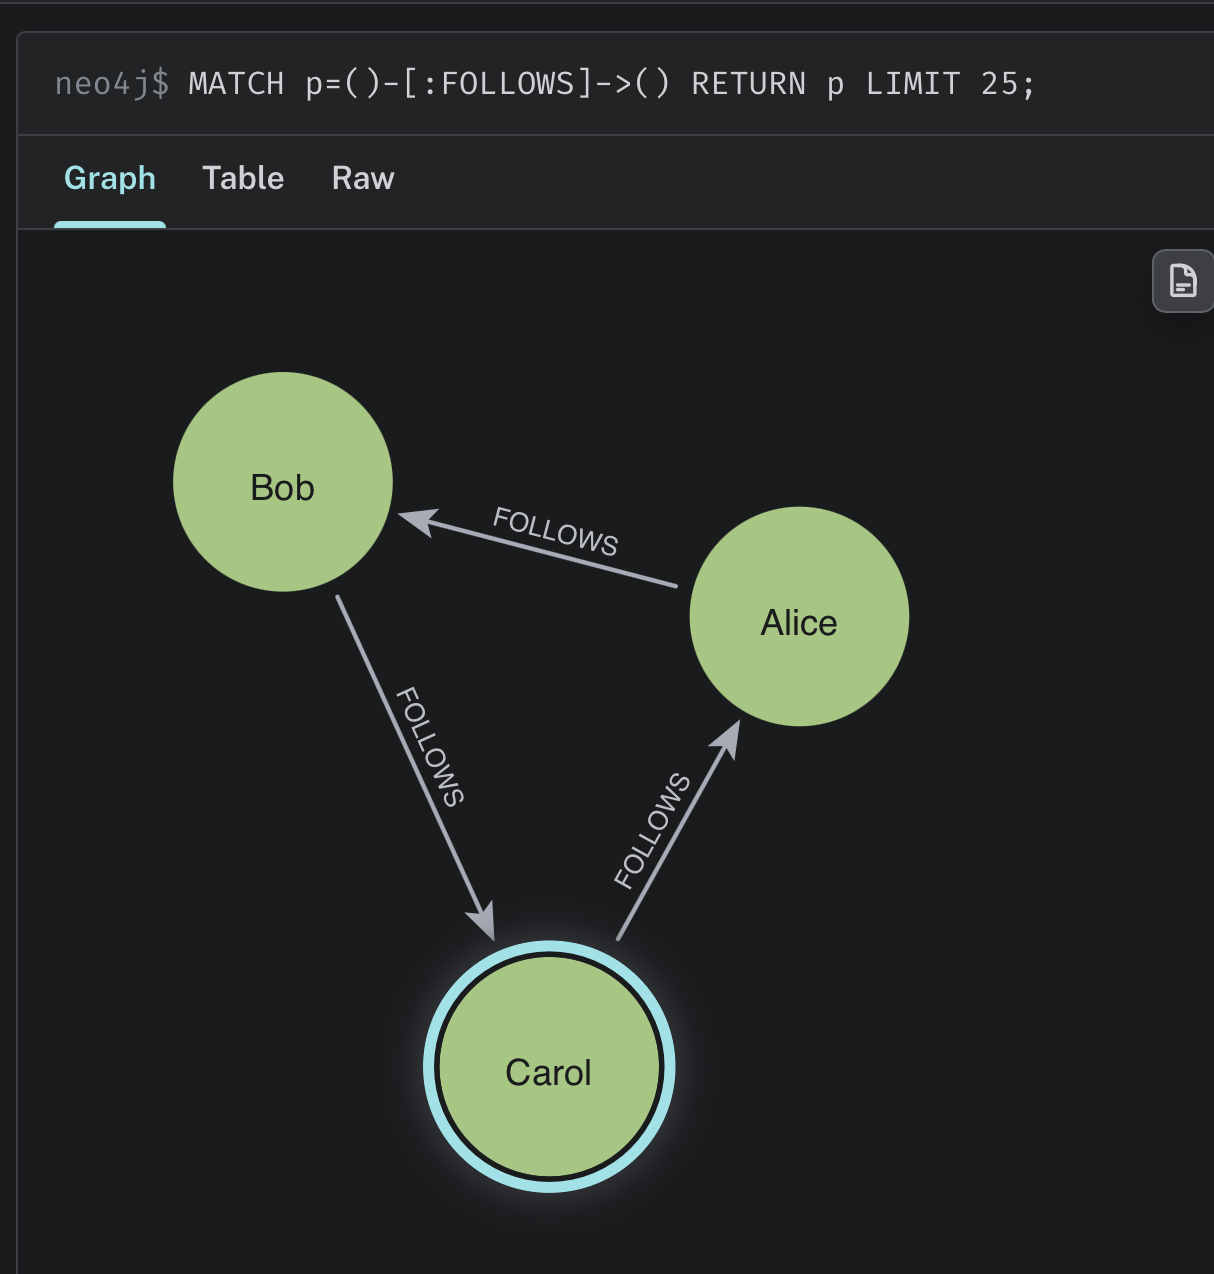

In [ ]:
su.spark.stop()